# Análisis y optimización de un portafolio de acciones

Este notebook construye, paso a paso, un portafolio con **cualquier cantidad de acciones**.
Cada sección explica *qué* se calcula y *por qué* importa, y luego lo muestra con tablas y gráficas.

**Ruta:** datos → rendimientos → métricas por activo → correlación → estimación → estrategias →
frontera eficiente → validación fuera de muestra → portafolio final → laboratorio interactivo.

> Esto es un ejercicio cuantitativo y educativo, no una recomendación de inversión.

In [37]:
# Librerías (todas viven en libs.py) y la lógica del análisis (acciones.py)
from libs import pd, np, plt, widgets, display, Markdown, replace
import acciones as ac

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

## 1. Elige tus acciones

Escribe en el panel las acciones que quieras analizar (símbolos de [Yahoo Finance](https://finance.yahoo.com),
p. ej. `AAPL`, `KO`, `WALMEX.MX`) y pulsa **Analizar**: todas las secciones de abajo se recalculan.

- **Desde:** inicio del periodo histórico. Más años = estimaciones más estables, pero quizá menos actuales.
- **Benchmark:** índice para comparar (SPY = S&P 500). Déjalo vacío para no usar ninguno.
- **Capital:** dinero a invertir, para calcular cuántas acciones comprar.

Los parámetros avanzados (peso máximo, estimadores, regularización, periodo de prueba) se exploran en los
**laboratorios** del final.

> En Jupyter, los valores iniciales están en la celda de abajo. Tras usar el panel, ejecuta las celdas
> siguientes (*Run Selected Cell and All Below*) para actualizar las secciones.

In [38]:
cfg_inicial = ac.Config(
    tickers=["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "JPM", "KO", "XOM"],
    inicio="2021-01-01",      # fin: por defecto, hoy
    benchmark="SPY",
    capital=10_000,
    # Avanzados (valores por defecto): max_peso=0.40, mu="historico", cov="ledoit-wolf",
    # gamma=0.1, test=0.30, rebalanceo="mensual"
)

tab = ac.Tablero()          # detecta si corre como app (Voilà) o como notebook
tab.analizar(cfg_inicial)
display(tab.panel())

Descargando 8 activos (2021-01-01 → 2026-11-11)...
  Activos válidos: AAPL, AMZN, GOOGL, JPM, KO, MSFT, NVDA, XOM
  Periodo efectivo: 2021-01-04 → 2026-11-10 (1471 días)


## 2. Datos: precios ajustados

Se usan **precios ajustados**: incorporan dividendos y *splits*, así que reflejan el rendimiento total real
(si una acción hace un split 2:1, el precio sin ajustar "cae" 50 % sin que nadie pierda dinero).

La limpieza descarta tickers inválidos o con historial demasiado corto (una acción que salió a bolsa hace poco
recortaría todo el periodo), rellena huecos cortos y alinea las fechas.

La **tasa libre de riesgo** es lo que ganarías sin riesgo (bonos del Tesoro a 3 meses, `^IRX`). Es la vara
para medir si el riesgo de las acciones "valió la pena".

**Cómo leer la gráfica:** todas parten de 100. Si una línea termina en 250, 100 invertidos se convirtieron
en 250. La línea punteada es el benchmark: lo que habrías obtenido comprando el índice completo.

**Tasa libre de riesgo promedio del periodo:** 3.29%

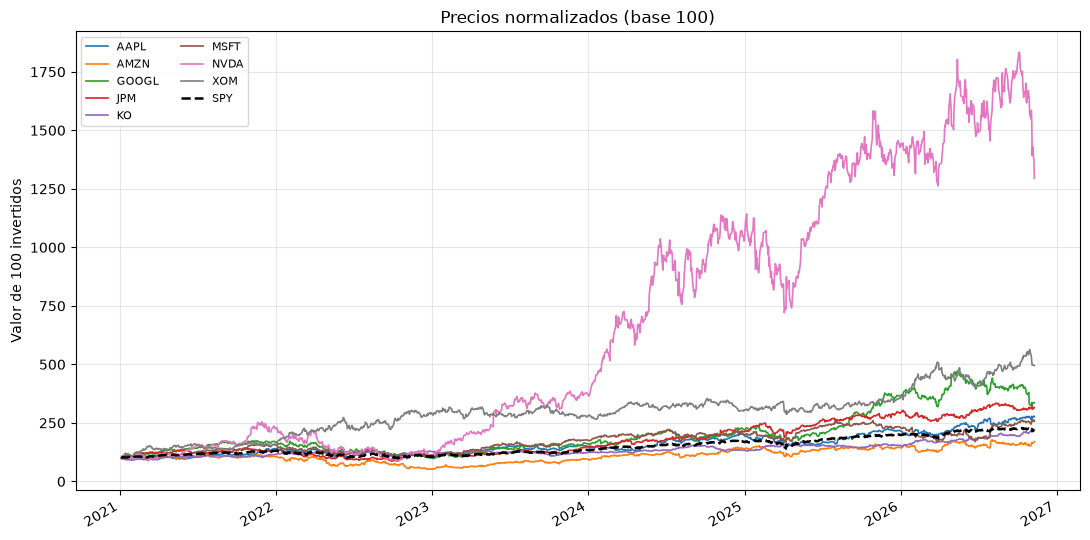

> **Tus resultados**
>
> - Periodo analizado: **2021-01-04 → 2026-11-10** (≈ 5.8 años, 8 acciones).
> - Mejor: **NVDA** (+1195%). Peor: **AMZN** (+70%).
> - **6 de 8** acciones superaron a SPY (+120%).

In [39]:
@tab.seccion
def _():
    A = tab.A
    display(Markdown(f"**Tasa libre de riesgo promedio del periodo:** {A.rf:.2%}"))
    ac.graf_precios(A.precios, A.bench); plt.show()
    display(Markdown(ac.lectura_precios(A.precios, A.bench)))

## 3. Rendimientos diarios

Los precios no son comparables entre sí (una acción de \$500 no es "mejor" que una de \$50); los **rendimientos** sí:

$$r_t = \frac{P_t}{P_{t-1}} - 1$$

Para anualizar se usa que hay ~252 días hábiles al año: la media se multiplica por 252 y la volatilidad por
$\sqrt{252}$ (la varianza crece con el tiempo; la desviación estándar, con su raíz).

**Cómo leer la gráfica:** la mayoría de los días se mueven cerca de 0 %, pero hay colas (días muy malos o muy
buenos). La línea roja es el **VaR 95 %**: en 1 de cada 20 días la pérdida fue *peor* que ese valor.
Colas más largas de lo que predice una campana normal = **curtosis** alta = sorpresas más frecuentes.

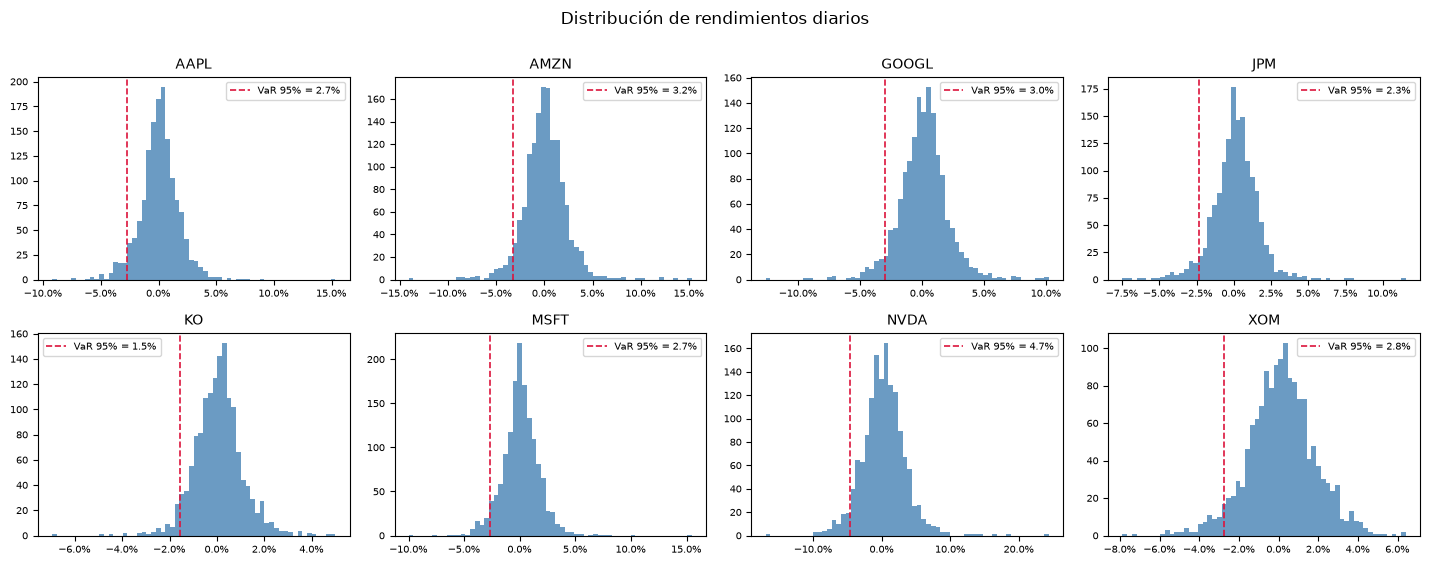

In [40]:
@tab.seccion
def _():
    ac.graf_distribucion(tab.A.rend)

## 4. Métricas por activo

| Métrica | Qué mide | Mejor si... |
|---|---|---|
| **CAGR** | Rendimiento anual compuesto realmente obtenido | Alto |
| **Volatilidad** | Desviación estándar anualizada: cuánto "se mueve" | Bajo |
| **Sharpe** | $\frac{R - R_f}{\sigma}$: rendimiento extra por unidad de riesgo | Alto (>1 es muy bueno) |
| **Sortino** | Como Sharpe, pero solo penaliza la volatilidad *a la baja* | Alto |
| **Máx. drawdown** | Peor caída desde un máximo hasta un mínimo | Cercano a 0 |
| **Calmar** | CAGR / \|máx. drawdown\| | Alto |
| **VaR / CVaR 95 %** | Pérdida diaria en el peor 5 % de días / promedio de ese peor 5 % | Bajo |
| **Asimetría** | Negativa = caídas grandes más frecuentes que subidas grandes | ≥ 0 |
| **Curtosis** | Colas gruesas (eventos extremos) | Bajo |
| **Beta** | Sensibilidad al mercado: beta 1.5 → si el mercado cae 10 %, tiende a caer 15 % | Depende |
| **Alfa** | Rendimiento que *no* explica el mercado (según CAPM) | Alto |
| **Information ratio** | Rendimiento extra vs. benchmark / variabilidad de esa diferencia | Alto |

**Cómo leer la gráfica:** arriba a la izquierda es el lugar ideal (mucho rendimiento, poco riesgo).
Dos acciones con el mismo rendimiento no son iguales si una lo logra con el doble de volatilidad.

,Rend. total,Rend. anual (CAGR),Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% diario,CVaR 95% diario,Asimetría,Curtosis,% días positivos,Beta,Alfa anual,Tracking error,Information ratio
AAPL,177.40%,19.11%,27.63%,0.65,0.96,-33.36%,0.57,2.70%,3.89%,0.35,6.10,52.93%,1.17,4.44%,19.75%,0.33
AMZN,70.00%,9.52%,35.14%,0.34,0.50,-56.15%,0.17,3.23%,4.84%,0.35,5.82,51.22%,1.45,-4.91%,26.53%,0.01
GOOGL,236.14%,23.10%,31.58%,0.71,1.04,-44.32%,0.52,2.99%,4.40%,-0.00,4.03,53.20%,1.25,7.98%,24.06%,0.45
JPM,215.39%,21.76%,24.04%,0.80,1.17,-38.77%,0.56,2.34%,3.48%,0.09,4.67,54.01%,0.87,9.19%,19.25%,0.40
KO,117.64%,14.26%,16.45%,0.70,1.02,-17.27%,0.83,1.55%,2.20%,-0.06,3.24,52.93%,0.26,8.44%,20.13%,-0.01
MSFT,156.86%,17.55%,27.41%,0.61,0.91,-37.15%,0.47,2.67%,3.67%,0.55,7.01,51.90%,1.13,3.48%,19.96%,0.25
NVDA,1194.55%,55.11%,50.56%,1.06,1.62,-66.34%,0.83,4.66%,6.56%,0.49,4.51,53.06%,2.10,28.95%,40.83%,1.02
XOM,394.63%,31.53%,27.21%,1.03,1.50,-20.51%,1.54,2.75%,3.78%,-0.18,1.07,53.81%,0.42,23.05%,28.05%,0.58
[SPY],119.54%,14.43%,16.69%,0.70,1.00,-24.50%,0.59,1.62%,2.42%,0.23,8.89,54.22%,1.00,0.00%,0.00%,-


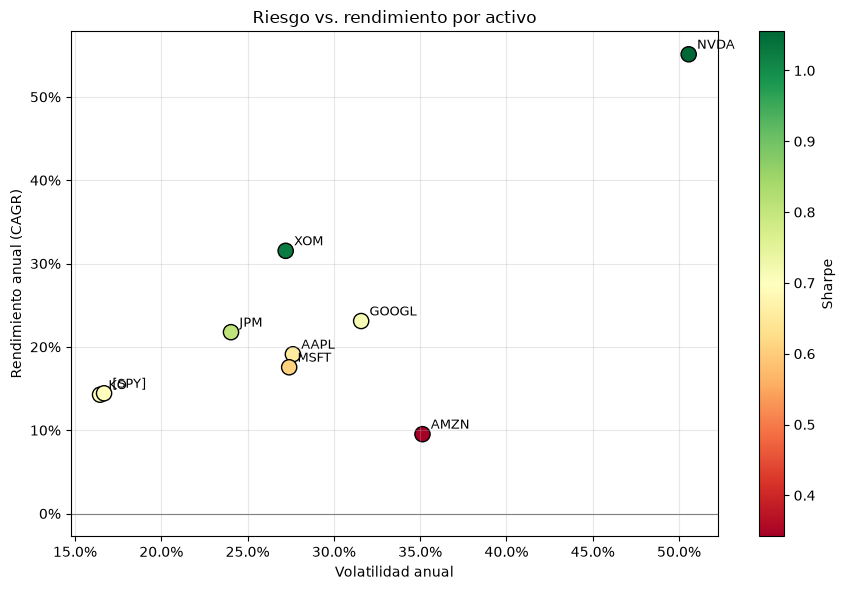

> **Tus resultados**
>
> - Mejor rendimiento por riesgo (Sharpe): **NVDA** (1.06); peor: **AMZN** (0.34).
> - Más volátil: **NVDA** (51% anual); más estable: **KO** (16%).
> - Peor caída: **NVDA** llegó a perder 66% desde su máximo.
> - Más sensible al mercado: **NVDA** (beta 2.10); más defensiva: **KO** (beta 0.26).

In [41]:
@tab.seccion
def _():
    A = tab.A
    display(ac.estilo(A.met_activos))
    ac.graf_riesgo_rendimiento(A.met_activos); plt.show()
    display(Markdown(ac.lectura_metricas(A.met_activos, A.rf)))

## 5. Correlación: la clave de la diversificación

La volatilidad de un portafolio **no** es el promedio de las volatilidades:

$$\sigma_p^2 = \sum_i \sum_j w_i w_j \sigma_i \sigma_j \rho_{ij}$$

Si dos activos tienen correlación $\rho$ baja, cuando uno cae el otro no necesariamente lo hace, y el portafolio
oscila menos que cada uno por separado. Es "el único almuerzo gratis" de las finanzas.

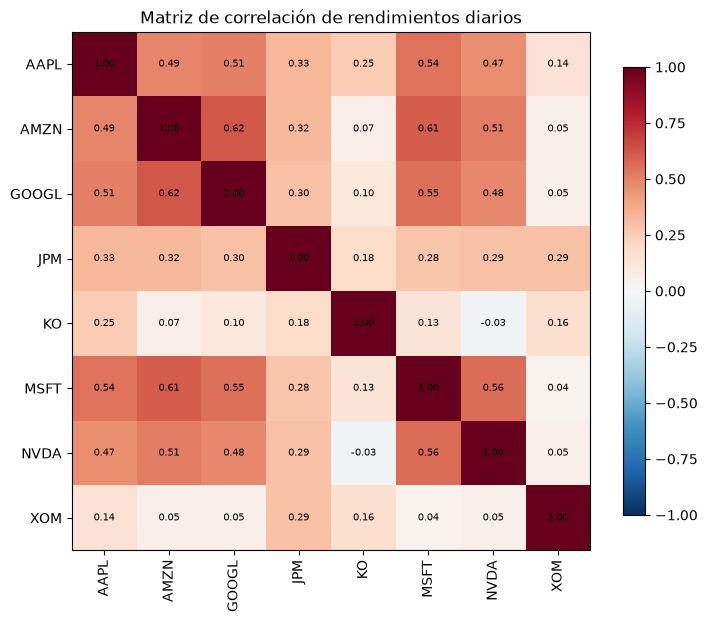

> **Tus resultados**
>
> - Correlación promedio **0.30**, baja: buena diversificación.
> - Par más parecido: **AMZN / GOOGL** (0.62). Par más complementario: **KO / NVDA** (-0.03).

In [42]:
@tab.seccion
def _():
    A = tab.A
    ac.graf_correlacion(A.corr); plt.show()
    if len(A.corr) > 1:
        altos, bajos = ac.pares_correlacion(A.corr)
        display(pd.concat({"Más correlacionados (diversifican poco)": altos.reset_index(),
                           "Menos correlacionados (diversifican más)": bajos.reset_index()}, axis=1)
                  .style.format(precision=2).hide(axis="index"))
    display(Markdown(ac.lectura_correlacion(A.corr)))

## 6. Estimar el futuro: rendimiento esperado (μ) y covarianza (Σ)

Optimizar requiere dos insumos: cuánto esperamos que rinda cada acción (**μ**) y cómo se mueven juntas (**Σ**).
Ambos se estiman con el pasado, y **ahí está el punto débil de toda la teoría**:

- **μ es muy ruidoso.** Con pocos años de datos, el error al estimar el rendimiento anual de una acción puede ser
  de ±10–15 puntos. El optimizador "se enamora" de quien tuvo suerte en el pasado.
- **Σ es más estable**, pero con muchos activos la matriz muestral es poco fiable. **Ledoit-Wolf** la "encoge"
  hacia una estructura más simple, lo que reduce errores extremos.

Por eso el análisis usa límites de peso, regularización y, sobre todo, **validación fuera de muestra** (sección 9).

In [43]:
@tab.seccion
def _():
    A = tab.A
    display(pd.DataFrame({
        "μ esperado": A.mu,
        "Volatilidad (Ledoit-Wolf)": np.sqrt(np.diag(A.S)),
        "Volatilidad (muestral)": np.sqrt(np.diag(A.S_muestral)),
    }).style.format("{:.2%}"))
    display(Markdown(f"**Número de condición de Σ** (más bajo = más estable al invertirla): "
                     f"muestral {np.linalg.cond(A.S_muestral):,.0f} · Ledoit-Wolf {np.linalg.cond(A.S):,.0f}"))

,μ esperado,Volatilidad (Ledoit-Wolf),Volatilidad (muestral)
Ticker,,,
AAPL,19.11%,27.66%,27.63%
AMZN,9.52%,35.09%,35.14%
GOOGL,23.10%,31.57%,31.58%
JPM,21.76%,24.13%,24.04%
KO,14.26%,16.69%,16.45%
MSFT,17.55%,27.45%,27.41%
NVDA,55.11%,50.38%,50.56%
XOM,31.53%,27.25%,27.21%


**Número de condición de Σ** (más bajo = más estable al invertirla): muestral 19 · Ledoit-Wolf 18

## 7. Siete estrategias para construir el portafolio

| Estrategia | Idea | Usa μ | Usa Σ |
|---|---|:-:|:-:|
| **Igual peso** | $1/N$ a cada acción. Simple y sorprendentemente difícil de superar | No | No |
| **Inversa volatilidad** | Más peso a las acciones menos volátiles | No | Solo diagonal |
| **Paridad de riesgo** | Cada acción aporta **el mismo riesgo** (no el mismo dinero) | No | Sí |
| **Mínima volatilidad** | El portafolio menos volátil posible | No | Sí |
| **Máximo Sharpe** | El de mejor rendimiento por unidad de riesgo (Markowitz clásico) | Sí | Sí |
| **Mínimo CVaR** | Minimiza la pérdida promedio en los peores días | Sí | (escenarios) |
| **HRP** | Agrupa acciones parecidas en un árbol y reparte riesgo entre grupos (López de Prado) | No | Sí |

Las que **no usan μ** son más robustas porque evitan el insumo más ruidoso.

**Activos efectivos** $= 1/\sum w_i^2$: con $N$ acciones a igual peso vale $N$; si casi todo está en una sola,
se acerca a 1. Mide qué tan diversificado está *realmente* el portafolio.

,Igual peso,Inversa volatilidad,Paridad de riesgo,Mínima volatilidad,Máximo Sharpe,Mínimo CVaR,HRP
Ticker,,,,,,,
AAPL,12.5%,12.4%,9.9%,10.3%,2.8%,-,11.7%
AMZN,12.5%,9.8%,8.2%,6.2%,-,-,4.7%
GOOGL,12.5%,10.9%,9.2%,9.1%,7.7%,-,5.9%
JPM,12.5%,14.3%,13.4%,16.0%,13.2%,18.3%,15.3%
KO,12.5%,20.6%,26.3%,26.7%,16.2%,40.0%,37.3%
MSFT,12.5%,12.5%,10.4%,12.1%,0.6%,21.7%,8.5%
NVDA,12.5%,6.8%,6.2%,1.3%,27.8%,-,2.5%
XOM,12.5%,12.6%,16.3%,18.4%,31.7%,19.9%,14.0%


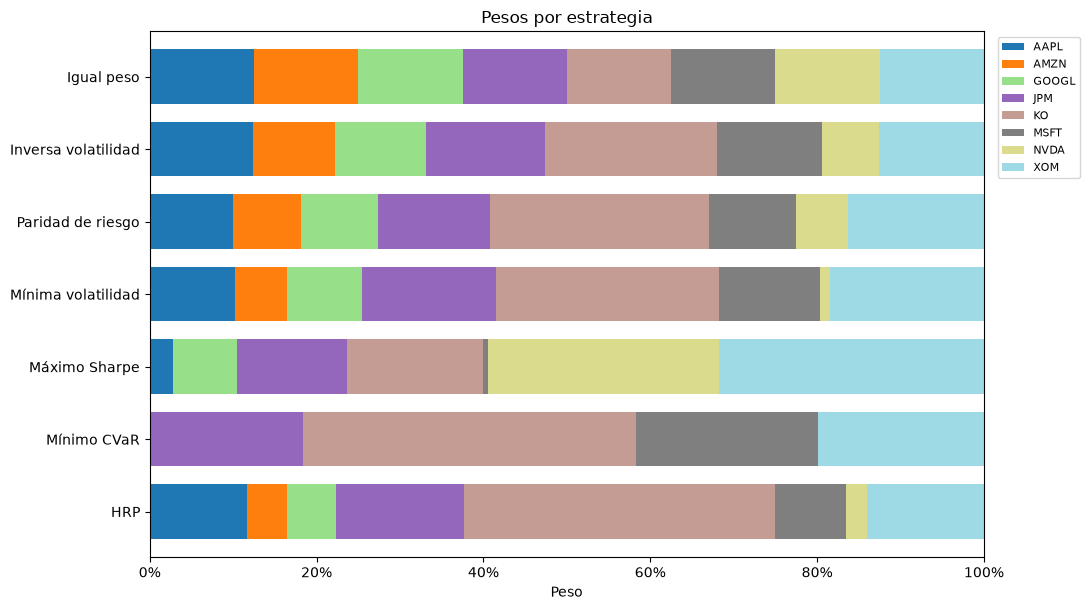

,Rend. esperado,Volatilidad esperada,Sharpe,N° activos,Activos efectivos
Igual peso,23.99%,19.50%,1.06,8.00,8.00
Inversa volatilidad,21.82%,17.02%,1.09,8.00,7.35
Paridad de riesgo,21.89%,15.78%,1.18,8.00,6.51
Mínima volatilidad,20.57%,14.94%,1.16,8.00,5.94
Máximo Sharpe,32.90%,20.44%,1.45,7.00,4.39
Mínimo CVaR,19.79%,13.83%,1.19,4.00,3.56
HRP,20.00%,14.29%,1.17,8.00,4.77


> **Tus resultados**
>
> - Estrategia más concentrada: **Mínimo CVaR** (equivale a 3.6 acciones a igual peso, de 8).
> - Mayor peso individual: **KO** con 40% en *Mínimo CVaR*.
> - Mejor Sharpe *esperado*: **Máximo Sharpe** (1.45), aún sin validar.

In [44]:
@tab.seccion
def _():
    A = tab.A
    display(ac.estilo_pesos(pd.DataFrame(A.pesos)))
    ac.graf_pesos(A.pesos); plt.show()
    display(ac.estilo(A.ex_ante, colorear=("Sharpe", "Activos efectivos")))
    display(Markdown(ac.lectura_pesos(A.pesos, A.ex_ante)))

## 8. Frontera eficiente

Cada punto de color es un portafolio aleatorio. La **línea negra** es la frontera eficiente: para cada nivel de
riesgo, el máximo rendimiento esperado posible. Ningún portafolio puede estar por encima de ella (según las estimaciones).

**Ojo:** esta gráfica usa las estimaciones de todo el historial, así que "Máximo Sharpe" siempre se ve espectacular
*aquí*. La pregunta real es si eso se mantiene en datos que el modelo no vio.

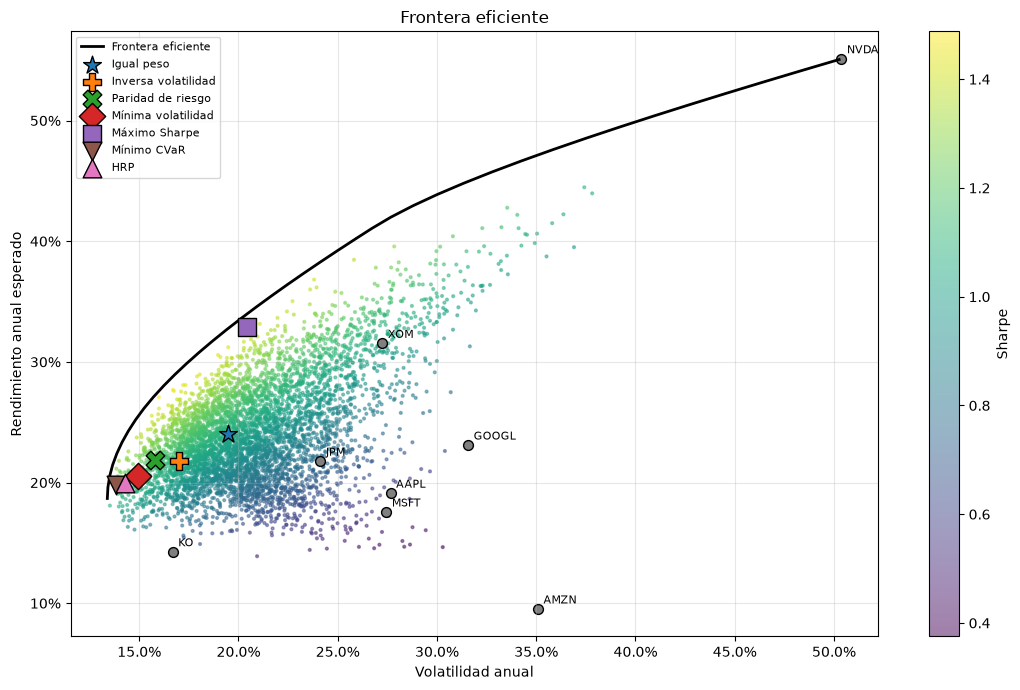

In [45]:
@tab.seccion
def _():
    A = tab.A
    ac.graf_frontera(A.mu, A.S, A.pesos, A.rf)

## 9. Validación fuera de muestra (la prueba de fuego)

1. Se toma la primera parte del periodo (*entrenamiento*) y con ella se calculan los pesos de cada estrategia.
2. Se "congela" ese portafolio y se mide qué pasó en la parte final (*prueba*), rebalanceando periódicamente.

Así se simula lo que habría vivido un inversionista real: decidir con la información disponible y luego esperar.
Si una estrategia brilla dentro de muestra pero no fuera, estaba **sobreajustada** (*overfitting*).

**Cómo leer las gráficas:** la primera muestra cuánto habrías ganado; la segunda, cuánto habrías sufrido en el
camino. La última compara el Sharpe dentro y fuera de muestra: las optimizaciones siempre lucen mejor con los datos
con los que fueron entrenadas.

**Entrenamiento (70%):** 2021-01-04 → 2025-02-06 · **Prueba (30%):** 2025-02-07 → 2026-11-10

,Rend. total,Rend. anual (CAGR),Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% diario,CVaR 95% diario,Asimetría,Curtosis,% días positivos,Beta,Alfa anual,Tracking error,Information ratio
HRP,53.85%,27.84%,12.56%,1.76,2.78,-11.97%,2.33,0.94%,1.53%,0.43,13.08,55.66%,0.47,16.77%,13.35%,0.80
Mínimo CVaR,52.88%,27.38%,12.74%,1.71,2.67,-9.45%,2.90,1.07%,1.57%,0.08,8.97,56.79%,0.36,17.60%,15.61%,0.66
Mínima volatilidad,52.30%,27.11%,13.37%,1.62,2.51,-14.18%,1.91,1.12%,1.75%,0.54,16.11,54.52%,0.57,15.10%,11.68%,0.87
Paridad de riesgo,51.53%,26.74%,13.86%,1.55,2.38,-15.43%,1.73,1.16%,1.87%,0.78,19.32,54.52%,0.66,13.88%,9.88%,1.01
Inversa volatilidad,49.66%,25.84%,14.97%,1.39,2.15,-16.86%,1.53,1.29%,2.03%,0.96,18.77,54.98%,0.74,12.34%,8.82%,1.06
Igual peso,47.34%,24.73%,17.23%,1.18,1.79,-19.26%,1.28,1.46%,2.39%,1.00,18.44,55.88%,0.89,10.07%,7.71%,1.15
Máximo Sharpe,49.08%,25.57%,21.66%,1.01,1.48,-20.18%,1.27,1.87%,3.03%,0.38,12.34,55.20%,0.94,11.09%,14.31%,0.73
[SPY],26.11%,14.14%,17.35%,0.66,0.97,-18.76%,0.75,1.57%,2.45%,1.10,21.94,54.07%,1.00,0.00%,0.00%,-


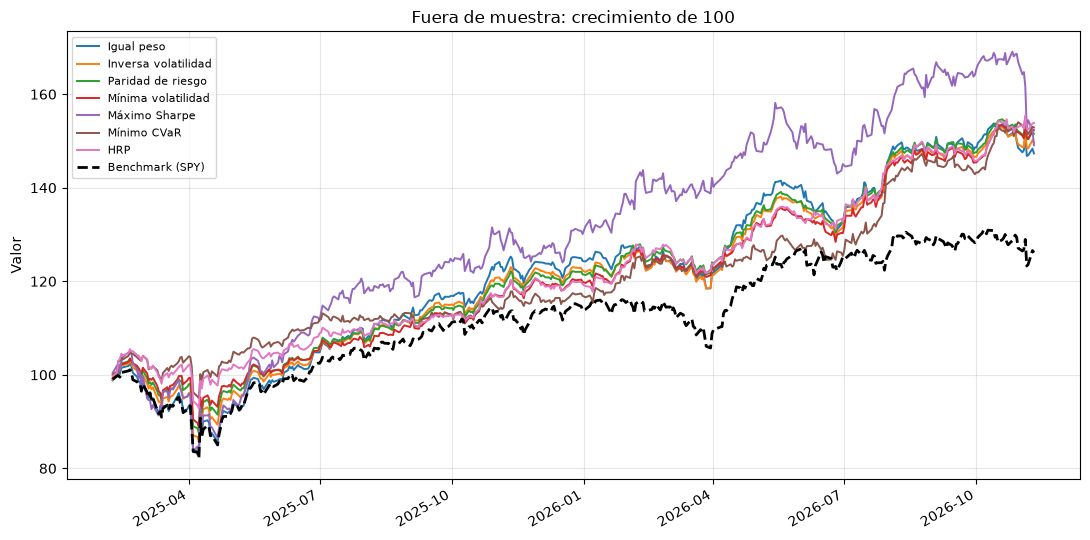

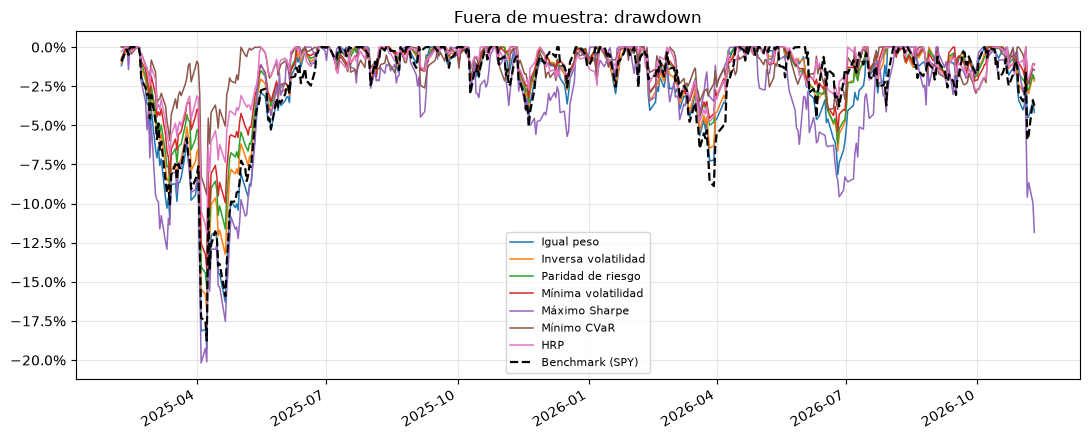

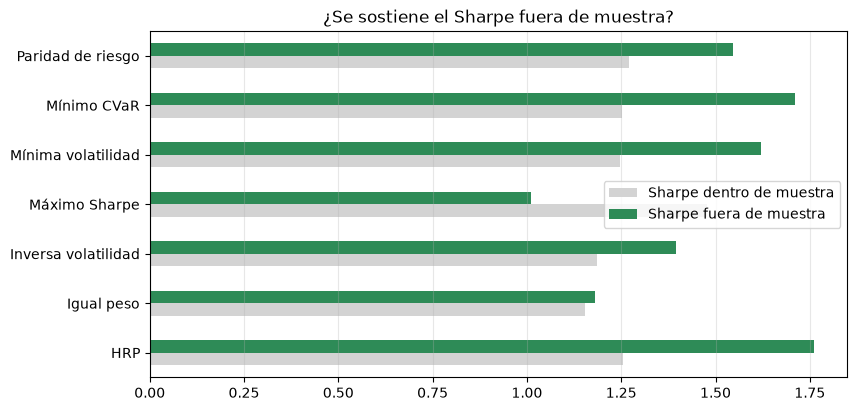

> **Tus resultados**
>
> - Ganadora fuera de muestra: **HRP** (Sharpe 1.76, CAGR 27.8%, peor caída -12.0%).
> - **7 de 7** estrategias superaron el Sharpe del benchmark (0.66).
> - *Máximo Sharpe* quedó #1 dentro de muestra y **#7** fuera de muestra: señal de sobreajuste.

In [46]:
@tab.seccion
def _():
    A, o = tab.A, tab.A.oos
    if o is None:
        display(Markdown("*No hay datos suficientes para validar fuera de muestra "
                         "(se necesita al menos 1 año de entrenamiento). Prueba con una fecha de inicio anterior.*"))
        return
    display(Markdown(f"**Entrenamiento ({1 - A.cfg.test:.0%}):** {o.periodo_train[0]} → {o.periodo_train[1]} · "
                     f"**Prueba ({A.cfg.test:.0%}):** {o.periodo_test[0]} → {o.periodo_test[1]}"))
    display(ac.estilo(o.metricas))
    ac.graf_crecimiento(o.rendimientos, o.benchmark, "Fuera de muestra: crecimiento de 100"); plt.show()
    ac.graf_drawdown(o.rendimientos, o.benchmark, "Fuera de muestra: drawdown"); plt.show()
    sharpe = pd.DataFrame({"Sharpe dentro de muestra": A.met_hist["Sharpe"],
                           "Sharpe fuera de muestra": o.metricas["Sharpe"]}).dropna()
    ax = sharpe.plot.barh(figsize=(9, 4.5), color=["lightgray", "seagreen"])
    ax.set_title("¿Se sostiene el Sharpe fuera de muestra?"); ax.grid(alpha=0.3, axis="x"); plt.show()
    display(Markdown(ac.lectura_oos(o, A.met_hist)))

## 10. Portafolio final

Se sugiere la estrategia que mejor se comportó en la validación (o, si no se pudo validar, la de mejor Sharpe
esperado), y sus pesos se recalculan con **todo** el historial: la información más completa disponible hoy.

La gráfica compara el **dinero** invertido en cada acción con el **riesgo** que aporta. Una acción con 10 % del
capital puede aportar 25 % del riesgo si es muy volátil o está muy correlacionada con las demás.

### Portafolio sugerido: **HRP**  
*Criterio: mejor Sharpe fuera de muestra*

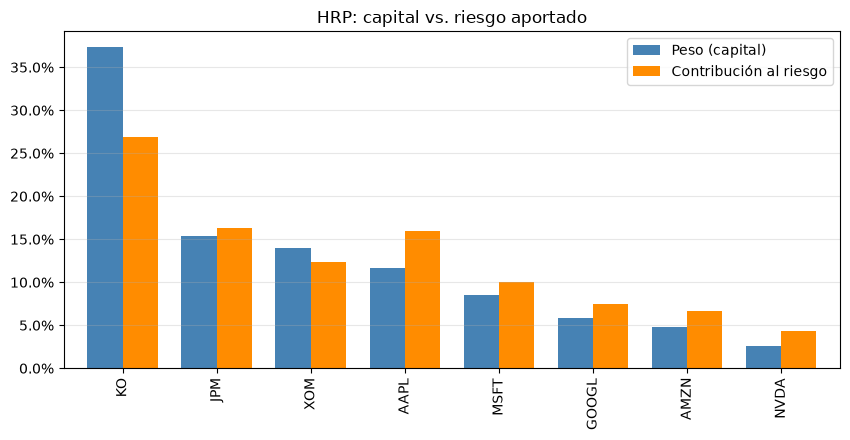

> **Tus resultados**
>
> - Mayor inversión: **KO** (37% del capital).
> - Mayor fuente de riesgo: **KO** (27% del riesgo con 37% del capital).

**Compra con $10,000** (precios del 2026-11-10). Efectivo sobrante: **$67.25**

,Acciones,Precio,Monto,Peso real,Peso objetivo
KO,38,$96.91,"$3,682.58",36.8%,37.3%
JPM,4,$342.07,"$1,368.28",13.7%,15.3%
XOM,8,$164.47,"$1,315.76",13.2%,14.0%
MSFT,2,$533.16,"$1,066.32",10.7%,8.5%
AAPL,3,$348.51,"$1,045.53",10.5%,11.7%
GOOGL,2,$287.38,$574.76,5.7%,5.9%
AMZN,2,$270.87,$541.74,5.4%,4.7%
NVDA,2,$168.89,$337.78,3.4%,2.5%


In [47]:
@tab.seccion
def _():
    A = tab.A
    display(Markdown(f"### Portafolio sugerido: **{A.elegido}**  \n*Criterio: {A.motivo}*"))
    ac.graf_contribucion(A.w, A.S, f"{A.elegido}: capital vs. riesgo aportado"); plt.show()
    display(Markdown(ac.lectura_final(A.elegido, A.w, A.S)))
    if A.cfg.capital:
        compra, sobrante = ac.asignacion_discreta(A.w, A.precios, A.cfg.capital)
        display(Markdown(f"**Compra con ${A.cfg.capital:,.0f}** (precios del {A.precios.index[-1].date()}). "
                         f"Efectivo sobrante: **${sobrante:,.2f}**"))
        display(compra.style.format({"Precio": "${:,.2f}", "Monto": "${:,.2f}",
                                     "Peso real": "{:.1%}", "Peso objetivo": "{:.1%}"}))

## 11. Laboratorio interactivo

Mueve los controles y observa cómo cambia el portafolio **sin volver a descargar datos**.
Preguntas para explorar:

- ¿Qué pasa con "Máximo Sharpe" si subes el peso máximo a 100 % y gamma a 0? (pista: se concentra)
- ¿Cambian mucho los pesos al pasar μ de `historico` a `capm`? Eso muestra cuán frágil es estimar rendimientos.
- ¿La paridad de riesgo cambia con μ? ¿Por qué no?

> Los controles requieren un kernel activo (Jupyter, VS Code o la app). En GitHub o nbviewer no responden.

In [ ]:
@tab.seccion
def _():
    A = tab.A
    estrategias = list(A.pesos)

    def laboratorio(estrategia, max_peso, gamma, mu_metodo, cov_metodo):
        c = replace(A.cfg, max_peso=max_peso, gamma=gamma, mu=mu_metodo, cov=cov_metodo)
        p = ac.construir_portafolios(A.precios, A.bench, c, A.rf)
        if estrategia not in p:
            print(f"'{estrategia}' no se pudo calcular con estos parámetros."); return
        m, s = ac.estimar_mu_S(A.precios, A.bench, c, A.rf)
        display(ac.estilo(ac.desempeño_ex_ante({estrategia: p[estrategia]}, m, s, A.rf), colorear=()))
        ac.graf_contribucion(p[estrategia], s, f"{estrategia}: capital vs. riesgo"); plt.show()
        ac.graf_frontera(m, s, p, A.rf, destacar=estrategia, n_aleatorios=2000); plt.show()

    display(ac.Tablero.interactivo(
        laboratorio,
        estrategia=widgets.Dropdown(options=estrategias, description="Estrategia",
                                    value="Máximo Sharpe" if "Máximo Sharpe" in estrategias else estrategias[0]),
        max_peso=widgets.FloatSlider(value=A.cfg.max_peso, min=0.10, max=1.0, step=0.05, description="Peso máx.",
                                     readout_format=".0%", continuous_update=False),
        gamma=widgets.FloatSlider(value=A.cfg.gamma, min=0, max=2, step=0.05, description="Gamma L2",
                                  continuous_update=False),
        mu_metodo=widgets.ToggleButtons(options=["historico", "ema", "capm"], value=A.cfg.mu, description="μ"),
        cov_metodo=widgets.ToggleButtons(options=["ledoit-wolf", "muestral"], value=A.cfg.cov, description="Σ"),
    ))

### Laboratorio 2: validación fuera de muestra

¿Cambia la estrategia ganadora si cambias el tamaño del periodo de prueba o la frecuencia de rebalanceo?
Si el ranking cambia mucho, ninguna estrategia es claramente superior: la diferencia era suerte.

In [ ]:
@tab.seccion
def _():
    A = tab.A

    def laboratorio_oos(test, rebalanceo):
        c = replace(A.cfg, test=test, rebalanceo=rebalanceo)
        o = ac.validar_fuera_de_muestra(A.precios, A.bench, c, A.rf)
        if o is None:
            return
        display(Markdown(f"**Entrenamiento:** {o.periodo_train[0]} → {o.periodo_train[1]} · "
                         f"**Prueba:** {o.periodo_test[0]} → {o.periodo_test[1]}"))
        display(ac.estilo(o.metricas[["Rend. anual (CAGR)", "Volatilidad", "Sharpe", "Máx. drawdown"]]))
        ac.graf_crecimiento(o.rendimientos, o.benchmark, "Fuera de muestra: crecimiento de 100"); plt.show()
        display(Markdown(ac.lectura_oos(o)))

    display(ac.Tablero.interactivo(
        laboratorio_oos,
        test=widgets.FloatSlider(value=A.cfg.test, min=0.10, max=0.60, step=0.05, description="% prueba",
                                 readout_format=".0%", continuous_update=False),
        rebalanceo=widgets.Dropdown(options=list(ac.REBALANCEOS), value=A.cfg.rebalanceo,
                                    description="Rebalanceo"),
    ))

## 12. Conclusiones y limitaciones

- **El pasado no se repite tal cual.** Todo se estima con historia; un periodo distinto puede dar pesos muy distintos.
- **Estimar rendimientos es lo más difícil.** En la literatura, las estrategias que solo usan riesgo (paridad de riesgo,
  HRP, mínima volatilidad) suelen sostenerse mejor fuera de muestra que "Máximo Sharpe". Revisa en la sección 9 si
  eso se cumplió con tus acciones.
- **Faltan costos reales:** comisiones, impuestos y *spread* al rebalancear no están incluidos.
- **Sesgo de supervivencia:** elegir acciones que hoy conocemos (porque les fue bien) infla los resultados históricos.
- **Diversificación sectorial:** si todas las acciones son del mismo sector, la correlación alta limita cuánto se puede
  reducir el riesgo.

Para un reporte rápido sin notebook:
```bash
python acciones.py AAPL MSFT KO XOM --capital 10000
```